# Mapping vegetation greenness with HLS (R)

**Question.** How green is the forest around the Pando aspen stand in midsummer, and which pixels can we trust?

By the end of this lesson you will have a map like this one, made from one clear satellite scene, and a saved file you can open in any GIS:

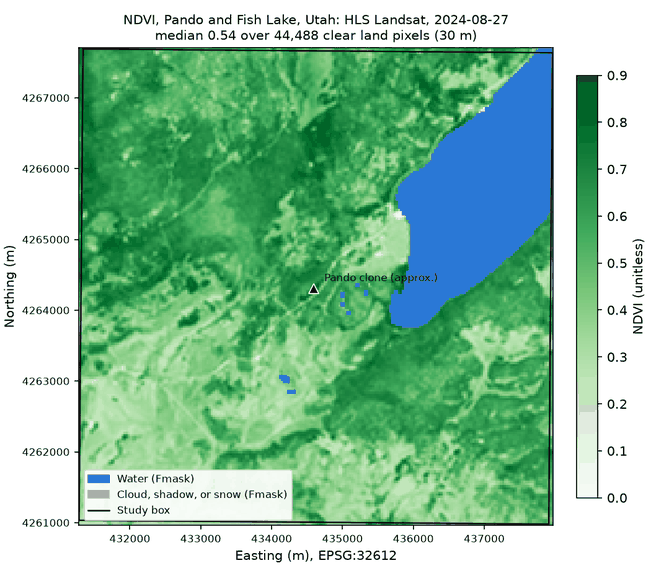

**You will learn to**

1. search NASA's catalog for Harmonized Landsat Sentinel-2 (HLS) data and judge which scenes actually show your study area clearly;
2. read only the study-area part of cloud-hosted files, then apply scale factors and the Fmask quality layer;
3. map the Normalized Difference Vegetation Index (NDVI) and save it with a record of how it was made.

This is the R version of the lesson. The [Python version](hls-vegetation-map-python.ipynb) follows the same steps and produces the same result.

## Before starting

- **Setup.** Run the [R getting-started notebook](../getting-started/getting-started-r.ipynb) first. You need the Trees from Space R environment, its kernel (**R 4.5 (Trees from Space)**), and an Earthdata Login stored in `~/.netrc` ([guide](../../docs/getting-started/earthdata-login.md)).
- **CHPC.** OnDemand sessions on compute nodes cannot download data. Either fetch the data first with a short transfer job, or run on a Frisco node, as described in the [CHPC guide](../../docs/getting-started/chpc.md). Once the data are cached, the whole notebook runs offline.
- **Data volume.** About 2 MB, read directly from NASA's servers and saved to the lesson cache. If you already ran the Python version, this notebook reuses its downloaded files.
- **Time.** About 20 minutes of reading and running. The first run spends a minute or two reading data; reruns take seconds.
- **Tested environments.** See the [lesson README](README.md). The R version has not been tested in Google Colab.

## The data in brief

**HLS** (Harmonized Landsat Sentinel-2, version 2.0) combines observations from the Landsat 8 and 9 satellites (product **HLSL30**) and the Sentinel-2A, 2B, and 2C satellites (product **HLSS30**). NASA processes both to surface reflectance on the same 30 m grid and adjusts them so they can be used together. Together they observe most places every two to four days. Data are stored in tiles about 110 km across, and each file holds one spectral band of one tile on one date. A set of files from one overpass is called a **granule**.

**Surface reflectance** is the fraction of sunlight the ground reflects in a wavelength band, from 0 to 1. The files store it as whole numbers multiplied by 10,000, so a stored value of 3,512 means a reflectance of 0.3512.

**NDVI** compares near-infrared (NIR) and red reflectance: NDVI = (NIR − Red) / (NIR + Red). Green leaves reflect strongly in the near-infrared and absorb red light, so dense green vegetation has high NDVI (about 0.6 to 0.9), while bare soil is near 0.1 to 0.2 and water is usually below 0. NDVI has no units.

**Limits to keep in mind.** NDVI is a proxy for green leaf cover, not a measure of biomass. It saturates in dense canopies, so it separates sparse from dense forest well but cannot tell a dense stand from a very dense one. The Fmask quality layer flags most clouds and shadows, but thin cloud, smoke, and the edges of shadows can slip through.

## Settings

Everything you might change is in the next cell. Coordinates are longitude and latitude in decimal degrees (WGS84), in the order **west, south, east, north**. Dates use the format `"YYYY-MM-DD"`. If you run this notebook as a batch job, the job uses the values saved in this cell.

In [ ]:
# Study area: a box of longitude/latitude in degrees, ordered (west, south, east, north).
SITE_ID <- "pando"
SITE_NAME <- "Pando and Fish Lake, Utah"
BBOX <- c(-111.788, 38.495, -111.712, 38.555)

# Search window. Mid-July to mid-September avoids snow at this mountain site.
START_DATE <- "2024-07-15"
END_DATE <- "2024-09-15"

# HLS products (Landsat and Sentinel-2) and their version.
PRODUCTS <- c("HLSL30", "HLSS30")
VERSION <- "2.0"

# Request limit: the most granules to consider per product.
MAX_GRANULES <- 40

# Fmask bits that make a pixel unusable: 1 cloud, 2 adjacent to cloud or shadow,
# 3 cloud shadow, 4 snow or ice. (Bit 5, water, is shown on the map instead.)
MASK_BITS <- c(1, 2, 3, 4)

# The chosen scene must have at least this fraction of clear pixels in the study area.
MIN_CLEAR_FRACTION <- 0.8

## Setup

The next cell loads the packages this lesson uses and sets up the folders for cached data and results. **terra** handles rasters, **sf** provides GDAL's command-line tools inside R, **rstac** searches catalogs, and **jsonlite** reads and writes JSON files.

In [ ]:
suppressPackageStartupMessages({
  library(terra)
  library(sf)
  library(rstac)
  library(jsonlite)
})
options(repr.plot.width = 7, repr.plot.height = 6.2, repr.plot.res = 110)
RUN_STARTED <- Sys.time()

find_repo_root <- function(start = getwd()) {
  # Walk up from `start` to the folder holding the .tfs-root marker file.
  folder <- normalizePath(start)
  repeat {
    if (file.exists(file.path(folder, ".tfs-root"))) return(folder)
    parent <- dirname(folder)
    if (parent == folder) return(NULL)
    folder <- parent
  }
}

env_or <- function(name, default) {
  value <- Sys.getenv(name)
  if (nzchar(value)) value else default
}

REPO_ROOT <- find_repo_root()
BASE_DIR <- if (is.null(REPO_ROOT)) getwd() else REPO_ROOT
CACHE_DIR <- env_or("TFS_CACHE_DIR", file.path(BASE_DIR, "cache"))
OUTPUT_DIR <- env_or("TFS_OUTPUT_DIR", file.path(BASE_DIR, "outputs"))

# One cache folder per study box, named by its coordinates, so the Python lesson finds the same files.
box_name <- paste(sprintf("%.4f", BBOX), collapse = "_")
SITE_CACHE <- file.path(CACHE_DIR, "hls", paste0(SITE_ID, "_", box_name))
LESSON_OUTPUT <- file.path(OUTPUT_DIR, "hls-vegetation-map", "r")
dir.create(SITE_CACHE, recursive = TRUE, showWarnings = FALSE)
dir.create(LESSON_OUTPUT, recursive = TRUE, showWarnings = FALSE)
cat("Cache:  ", SITE_CACHE, "\n")
cat("Results:", LESSON_OUTPUT, "\n")

### Helpers for reading data once

Downloading the same data every time you rerun a notebook wastes time, and on CHPC compute nodes it is not even possible. The next cell defines a few small functions that save every piece of downloaded data in the cache and reuse it on later runs. Each file is first written under a temporary name and renamed only when complete, so an interrupted run never leaves a half-written file that looks finished.

The environment variables at the top configure GDAL, the library that terra and sf use to read the satellite files. They tell it to use your `~/.netrc` credentials, to keep NASA's login cookies in a private folder, and to retry a few times before giving up.

In [ ]:
NETRC_PATH <- env_or("NETRC", path.expand("~/.netrc"))
cookie_dir <- path.expand("~/.cache/trees-from-space")
dir.create(cookie_dir, recursive = TRUE, showWarnings = FALSE)
Sys.chmod(cookie_dir, mode = "0700")
cookie_file <- file.path(cookie_dir, "earthdata-cookies.txt")
Sys.setenv(
  GDAL_HTTP_NETRC = "YES",
  GDAL_HTTP_NETRC_FILE = NETRC_PATH,
  GDAL_HTTP_COOKIEFILE = cookie_file,
  GDAL_HTTP_COOKIEJAR = cookie_file,
  GDAL_DISABLE_READDIR_ON_OPEN = "EMPTY_DIR",
  CPL_VSIL_CURL_ALLOWED_EXTENSIONS = ".tif",
  GDAL_HTTP_MAX_RETRY = "4",
  GDAL_HTTP_RETRY_DELAY = "2",
  GDAL_HTTP_CONNECTTIMEOUT = "10",
  GDAL_HTTP_TIMEOUT = "60"
)

network_available <- function(host = "cmr.earthdata.nasa.gov", timeout_s = 5) {
  # Return TRUE if an HTTPS request to NASA succeeds.
  if (Sys.getenv("TFS_OFFLINE") == "1") return(FALSE)  # lets you test the offline route
  handle <- curl::new_handle(connecttimeout = timeout_s, timeout = 3 * timeout_s, nobody = TRUE)
  tryCatch({
    curl::curl_fetch_memory(paste0("https://", host, "/search/"), handle = handle)
    TRUE
  }, error = function(e) FALSE)
}

offline_message <- function(missing) {
  paste0(
    "This machine cannot reach NASA, and the cache does not yet hold ", basename(missing), ". ",
    "Run the notebook once on a machine with internet access (on CHPC, a transfer job ",
    "or a Frisco node; see docs/getting-started/chpc.md), then rerun it here."
  )
}

write_atomically <- function(path, write) {
  # Call write(temporary_path), then rename the result to `path`.
  temporary <- paste0(path, ".part")
  write(temporary)
  file.rename(temporary, path)
}

check_credentials <- function() {
  # Stop with a clear message if ~/.netrc has no Earthdata entry.
  ok <- file.exists(NETRC_PATH) &&
    any(grepl("urs.earthdata.nasa.gov", readLines(NETRC_PATH, warn = FALSE), fixed = TRUE))
  if (!ok) {
    stop("No Earthdata credentials in ", NETRC_PATH,
         ". See docs/getting-started/earthdata-login.md.", call. = FALSE)
  }
}

ONLINE <- network_available()
cat(if (ONLINE) "Network: online\n" else "Network: offline (only cached data can be used)\n")

## 1. Find granules and inspect the results

NASA's Common Metadata Repository (CMR) is the catalog of NASA Earth science data. It also offers a **STAC** interface (SpatioTemporal Asset Catalog), a common standard for describing geospatial data, which the **rstac** package searches. In STAC terms, HLS products are **collections** (`HLSL30_2.0` and `HLSS30_2.0`), each granule is an **item**, and each band file is an **asset**. Searching does not need a login.

The next cell keeps the properties we need from each item, including the **tile-wide** cloud cover (`eo:cloud_cover`) that NASA computed for the whole 110 km tile. The granule ID encodes the product, tile, year, day of year, and time in UTC: `HLS.S30.T12SVH.2024197T181919.v2.0` is a Sentinel-2 granule of tile 12SVH from day 197 of 2024 (July 15) at 18:19:19 UTC. For Landsat (L30) the near-infrared band is `B05`, and for Sentinel-2 (S30) it is `B8A`. HLS uses Sentinel-2's narrow near-infrared band because it matches Landsat's.

In [ ]:
STAC_URL <- "https://cmr.earthdata.nasa.gov/stac/LPCLOUD"
BANDS <- list(HLSL30 = c(red = "B04", nir = "B05"), HLSS30 = c(red = "B04", nir = "B8A"))

granule_record <- function(item, product) {
  # Keep the properties of one search result that this lesson uses.
  bands <- c(Fmask = "Fmask", BANDS[[product]])
  list(
    granule_id = item$id,
    product = product,
    datetime_utc = item$properties$datetime,
    tile = strsplit(item$id, ".", fixed = TRUE)[[1]][3],
    tile_cloud_pct = item$properties[["eo:cloud_cover"]],
    urls = lapply(as.list(bands), function(band) item$assets[[band]]$href)
  )
}

load_or_search <- function(product) {
  # Return search results for one product, from the cache when possible.
  path <- file.path(SITE_CACHE, sprintf("search_stac_%s_v%s_%s_%s_max%d.json",
                                        product, VERSION, START_DATE, END_DATE, MAX_GRANULES))
  if (file.exists(path)) {
    cat(product, ": ", basename(path), " (cached)\n", sep = "")
    return(fromJSON(path, simplifyVector = FALSE))
  }
  if (!ONLINE) stop(offline_message(path), call. = FALSE)
  items <- stac(STAC_URL) |>
    stac_search(
      collections = paste0(product, "_", VERSION),
      bbox = BBOX,
      datetime = paste0(START_DATE, "T00:00:00Z/", END_DATE, "T23:59:59Z"),
      limit = MAX_GRANULES
    ) |>
    post_request()
  records <- lapply(items$features, granule_record, product = product)
  write_atomically(path, function(tmp) write_json(records, tmp, auto_unbox = TRUE, pretty = TRUE))
  cat(product, ": ", length(records), " granules found (searched NASA's catalog)\n", sep = "")
  records
}

records <- unlist(lapply(PRODUCTS, load_or_search), recursive = FALSE)
if (length(records) == 0) {
  stop("No HLS granules matched. Check that BBOX is ordered (west, south, east, north), ",
       "that START_DATE comes before END_DATE, and that the dates fall within the HLS ",
       "record (Landsat from April 2013, Sentinel-2 from November 2015).", call. = FALSE)
}

granules <- data.frame(
  granule_id = vapply(records, `[[`, "", "granule_id"),
  product = vapply(records, `[[`, "", "product"),
  date = as.Date(substr(vapply(records, `[[`, "", "datetime_utc"), 1, 10)),
  tile = vapply(records, `[[`, "", "tile"),
  tile_cloud_pct = vapply(records, function(r) as.numeric(r$tile_cloud_pct), 0)
)
urls <- setNames(lapply(records, `[[`, "urls"), granules$granule_id)
granules

The table shows every granule found: its product, date, tile, and the percentage of the whole tile that NASA flagged as cloud or cloud shadow (`tile_cloud_pct`). The catalog matched these granules because their **footprints** overlap our box. That says nothing yet about whether our box is clear, or even covered, in each one.

HLS tiles overlap their neighbors by about 10 km, so a study area near a tile edge can appear in two tiles with slightly different grids. Using a single tile keeps every image on the same grid. The next cell keeps the most common tile.

In [ ]:
tile_counts <- sort(table(granules$tile), decreasing = TRUE)
TILE <- names(tile_counts)[1]
if (length(tile_counts) > 1) {
  cat("The box touches tiles", paste(names(tile_counts), collapse = ", "), "; using", TILE, "only.\n")
}
granules <- granules[granules$tile == TILE, ]
cat(nrow(granules), " granules from tile ", TILE, ": ",
    sum(granules$product == "HLSL30"), " Landsat (L30), ",
    sum(granules$product == "HLSS30"), " Sentinel-2 (S30)\n", sep = "")

## 2. Check the study area in each granule

Each HLS granule includes an **Fmask** quality layer: one byte per pixel, in which individual bits flag cloud, cloud shadow, snow, water, and more. Bit 0 is the rightmost bit. For example, the value 66 is `01000010` in binary: bit 1 (cloud) is set, and bits 6 and 7 hold an aerosol level that we do not use here. A value of 255 means there is no data for that pixel.

| Bit | Meaning | Used here |
| --- | --- | --- |
| 1 | Cloud | Masked |
| 2 | Adjacent to cloud or shadow | Masked |
| 3 | Cloud shadow | Masked |
| 4 | Snow or ice | Masked |
| 5 | Water | Shown on the map |
| 6–7 | Aerosol level | Not used |

The files are **Cloud Optimized GeoTIFFs**, stored in blocks so that a program can read part of a file without downloading all of it. The next cell works out which pixels of the tile cover our box, copies that window of each granule's Fmask layer to the cache with GDAL's `translate` tool, and computes the **clear fraction**: the share of the box's pixels that have data and none of the masked flags. Pixels without data count against a granule.

The box is defined in longitude and latitude, but HLS files use a UTM map projection in meters. The window therefore covers the box's footprint in UTM, rounded outward to whole 30 m pixels, so it is slightly larger than the box itself. Because the window's edges fall exactly on pixel edges, `translate` copies the stored values unchanged, along with their scale factor and other metadata.

In [ ]:
FMASK_FILL <- 255
WATER_BIT <- 5

aoi_window <- function(src) {
  # Map coordinates (xmin, ymax, xmax, ymin) of the pixels covering BBOX, rounded outward.
  steps <- seq(0, 1, length.out = 23)
  w <- BBOX[1]; s <- BBOX[2]; e <- BBOX[3]; n <- BBOX[4]
  lon <- c(w + (e - w) * steps, rep(e, 23), e - (e - w) * steps, rep(w, 23))
  lat <- c(rep(s, 23), s + (n - s) * steps, rep(n, 23), n - (n - s) * steps)
  xy <- project(cbind(lon, lat), from = "EPSG:4326", to = crs(src))
  x0 <- xmin(src); y0 <- ymax(src); size <- res(src)[1]
  col0 <- floor((min(xy[, 1]) - x0) / size); col1 <- ceiling((max(xy[, 1]) - x0) / size)
  row0 <- floor((y0 - max(xy[, 2])) / size); row1 <- ceiling((y0 - min(xy[, 2])) / size)
  c(x0 + col0 * size, y0 - row0 * size, x0 + col1 * size, y0 - row1 * size)
}

read_aoi_window <- function(url) {
  # Return list(path, status) for the cached study-area window of one remote file.
  path <- file.path(SITE_CACHE, sub("\\.tif$", ".aoi.tif", basename(url)))
  if (file.exists(path)) return(list(path = path, status = "cached"))
  if (!ONLINE) stop(offline_message(path), call. = FALSE)
  check_credentials()
  remote <- paste0("/vsicurl/", url)
  window <- aoi_window(rast(remote))  # opening reads only the file header
  write_atomically(path, function(tmp) {
    gdal_utils("translate", remote, tmp,
               options = c("-of", "GTiff", "-projwin", window, "-co", "COMPRESS=DEFLATE"))
  })
  list(path = path, status = "downloaded")
}

fmask_bit <- function(values, bit) {
  # TRUE where the given bit of the Fmask byte is set.
  bitwAnd(values, bitwShiftL(1L, bit)) > 0
}

fmask_classes <- function(fmask) {
  # Split pixels into no data, masked, water, and clear (vectors in cell order).
  v <- values(fmask, mat = FALSE)
  no_data <- is.na(v) | v == FMASK_FILL  # terra reads the fill value 255 as NA
  v[no_data] <- 0L
  masked <- rep(FALSE, length(v))
  for (bit in MASK_BITS) masked <- masked | fmask_bit(v, bit)
  masked <- masked & !no_data
  clear <- !no_data & !masked
  water <- clear & fmask_bit(v, WATER_BIT)
  list(no_data = no_data, masked = masked, water = water, clear = clear)
}

statuses <- character(0)
granules$aoi_clear_pct <- NA_real_
granules$aoi_data_pct <- NA_real_
for (i in seq_len(nrow(granules))) {
  window_file <- read_aoi_window(urls[[granules$granule_id[i]]]$Fmask)
  statuses <- c(statuses, window_file$status)
  fmask <- rast(window_file$path, raw = TRUE)
  classes <- fmask_classes(fmask)
  granules$aoi_clear_pct[i] <- 100 * sum(classes$clear) / ncell(fmask)
  granules$aoi_data_pct[i] <- 100 * sum(!classes$no_data) / ncell(fmask)
}
cat("Fmask windows:", sum(statuses == "downloaded"), "downloaded,", sum(statuses == "cached"), "cached\n")
cat("Window:", ncol(fmask), "x", nrow(fmask), "pixels of 30 m, about", round(ncell(fmask) / 1e3),
    "KB per Fmask window before compression\n")

Now rank the granules. The best granule has the highest clear fraction in the study area. Ties are broken by the share of the box with any data, then by the date closest to the middle of the search window, then by granule ID, so the choice is always the same.

The plot compares NASA's tile-wide cloud estimate with what we measured inside the box. If the box were typical of the tile, the points would fall along the dashed line. Points far from it show why it pays to check the study area itself.

In [ ]:
start <- as.Date(START_DATE); end <- as.Date(END_DATE)
middle <- start + floor(as.numeric(end - start) / 2)
granules$days_from_middle <- abs(as.numeric(granules$date - middle))
granules <- granules[order(-granules$aoi_clear_pct, -granules$aoi_data_pct,
                           granules$days_from_middle, granules$granule_id), ]
rownames(granules) <- NULL
best <- granules[1, ]

if (best$aoi_clear_pct < 100 * MIN_CLEAR_FRACTION) {
  stop(sprintf(paste0("No granule has at least %.0f%% clear pixels in the study area (best: %.0f%%). ",
                      "Widen the date window or lower MIN_CLEAR_FRACTION."),
               100 * MIN_CLEAR_FRACTION, best$aoi_clear_pct), call. = FALSE)
}

STYLE <- list(HLSL30 = list(col = "#2a78d6", pch = 16, label = "Landsat (L30)"),
              HLSS30 = list(col = "#eb6834", pch = 15, label = "Sentinel-2 (S30)"))
options(repr.plot.width = 6.5, repr.plot.height = 4.5)
par(mar = c(4.2, 4.2, 2.5, 1), las = 1, cex.axis = 0.8)
plot(NA, xlim = c(0, 100), ylim = c(0, 100), bty = "l",
     xlab = "Tile-wide cloud and shadow (%, from NASA metadata)",
     ylab = "Clear pixels in the study area (%)",
     main = sprintf("Which granules show the study area clearly? (%s to %s)", START_DATE, END_DATE),
     cex.main = 0.9, font.main = 1)
grid(col = "#e4e3df", lty = 1)
abline(a = 100, b = -1, lty = 2, col = "#8a8984")
text(64, 40, "box as cloudy as the tile", srt = -33, cex = 0.7, col = "#52514e")
for (product in names(STYLE)) {
  rows <- granules$product == product
  points(granules$tile_cloud_pct[rows], granules$aoi_clear_pct[rows],
         col = STYLE[[product]]$col, pch = STYLE[[product]]$pch, cex = 1.1)
}
points(best$tile_cloud_pct, best$aoi_clear_pct, cex = 2.6, lwd = 1.2, col = "#0b0b0b")
text(best$tile_cloud_pct + 2, best$aoi_clear_pct - 6, paste("selected:", best$date), adj = 0,
     cex = 0.7, col = "#0b0b0b")
legend("bottomleft", legend = vapply(STYLE, `[[`, "", "label"),
       col = vapply(STYLE, `[[`, "", "col"), pch = vapply(STYLE, `[[`, 0, "pch"), bty = "n", cex = 0.8,
       inset = c(0.02, 0.02))
options(repr.plot.width = 7, repr.plot.height = 6.2)

head(granules[, c("granule_id", "product", "date", "tile_cloud_pct", "aoi_clear_pct", "aoi_data_pct")], 8)

## 3. Read and prepare the selected granule

Now read the red and near-infrared windows of the selected granule. Before computing NDVI, convert the stored integers to reflectance. Each file records its own **scale factor** and **offset** (reflectance = stored value × scale + offset).

terra applies the scale and offset automatically when it reads a file. To make the step visible, this lesson opens the windows with `raw = TRUE`, which returns the stored integers, reads the scale and offset with `scoff()`, and applies them itself. In your own work, letting terra apply them is fine once you have checked that the file carries them. Stored values of −9999 mean "no observation" and terra reads them as missing values (`NA`).

In [ ]:
HLS_SCALE <- 0.0001  # documented in the HLS v2.0 user guide

to_reflectance <- function(path, name) {
  # Read stored integers and convert them to reflectance (missing values stay NA).
  scale_offset <- scoff(rast(path))[1, ]
  scale <- scale_offset[["scale"]]; offset <- scale_offset[["offset"]]
  if (scale == 1) {  # the file carries no scale factor
    cat("Note:", name, "has no scale factor in its metadata; using", HLS_SCALE, "\n")
    scale <- HLS_SCALE; offset <- 0
  }
  stored <- values(rast(path, raw = TRUE), mat = FALSE)
  list(values = as.numeric(stored) * scale + offset, scale = scale, offset = offset)
}

best_urls <- urls[[best$granule_id]]
fmask_file <- read_aoi_window(best_urls$Fmask)
red_file <- read_aoi_window(best_urls$red)
nir_file <- read_aoi_window(best_urls$nir)
statuses <- c(statuses, red_file$status, nir_file$status)

template <- rast(red_file$path, raw = TRUE)
stopifnot(compareGeom(template, rast(nir_file$path), rast(fmask_file$path)))
red <- to_reflectance(red_file$path, "red")
nir <- to_reflectance(nir_file$path, "near-infrared")
classes <- fmask_classes(rast(fmask_file$path, raw = TRUE))

cat("Selected:", best$granule_id, paste0("(", best$product, ", ", best$date, ")\n"))
cat("Red and NIR windows:", red_file$status, nir_file$status, "\n")
cat("Scale and offset used: red", red$scale, "/", red$offset, ", NIR", nir$scale, "/", nir$offset, "\n")
cat(sprintf("Red reflectance of clear pixels: %.3f to %.3f\n",
            min(red$values[classes$clear], na.rm = TRUE), max(red$values[classes$clear], na.rm = TRUE)))
cat(sprintf("NIR reflectance of clear pixels: %.3f to %.3f\n",
            min(nir$values[classes$clear], na.rm = TRUE), max(nir$values[classes$clear], na.rm = TRUE)))

Reflectance should fall between 0 and 1. A few values slightly below 0 can occur over dark surfaces, such as water and deep shadow, because atmospheric correction is not perfect. If you see values in the thousands, the scale factor was not applied.

## 4. Compute and map NDVI

NDVI is computed only for clear pixels. Masked pixels and pixels without data become `NA`, and so does any pixel where NIR + Red is zero, to avoid dividing by zero. Water keeps its NDVI value but is drawn in blue on the map and left out of the summary, which describes the land.

In [ ]:
ndvi_values <- (nir$values - red$values) / (nir$values + red$values)
ndvi_values[which(nir$values + red$values == 0)] <- NA
ndvi_values[!classes$clear] <- NA

land <- !is.na(ndvi_values) & !classes$water
summary_row <- list(
  site_id = SITE_ID,
  granule_id = best$granule_id,
  product = best$product,
  date = as.character(best$date),
  aoi_pixels = length(ndvi_values),
  clear_land_pixels = sum(land),
  water_pixels = sum(classes$water),
  masked_pixels = sum(classes$masked),
  no_data_pixels = sum(classes$no_data),
  clear_fraction = round(sum(classes$clear) / length(ndvi_values), 4),
  ndvi_median = round(median(ndvi_values[land]), 4),
  ndvi_p25 = round(unname(quantile(ndvi_values[land], 0.25)), 4),
  ndvi_p75 = round(unname(quantile(ndvi_values[land], 0.75)), 4)
)
str(summary_row)

In [ ]:
ndvi <- rast(template)  # same grid as the red window, no values yet
values(ndvi) <- ndvi_values
names(ndvi) <- "NDVI (unitless)"
land_ndvi <- ndvi
values(land_ndvi) <- ifelse(land, ndvi_values, NA)
water_layer <- rast(template)  # drawn on top of NDVI in single colors
values(water_layer) <- ifelse(classes$water, 1, NA)
masked_layer <- rast(template)
values(masked_layer) <- ifelse(classes$masked, 1, NA)

# The study box, densified and converted from longitude/latitude to the map's UTM coordinates.
steps <- seq(0, 1, length.out = 50)
w <- BBOX[1]; s <- BBOX[2]; e <- BBOX[3]; n <- BBOX[4]
box_ll <- cbind(c(w + (e - w) * steps, rep(e, 50), e - (e - w) * steps, rep(w, 50)),
                c(rep(s, 50), s + (n - s) * steps, rep(n, 50), n - (n - s) * steps))
box_xy <- project(box_ll, from = "EPSG:4326", to = crs(template))
WATER_COLOR <- "#2a78d6"; MASKED_COLOR <- "#b5b4ae"
sensor <- if (best$product == "HLSL30") "Landsat" else "Sentinel-2"
epsg <- paste0("EPSG:", crs(template, describe = TRUE)$code)

draw_map <- function() {
  plot(land_ndvi, col = hcl.colors(100, "Greens", rev = TRUE), range = c(0, 0.9), fill_range = TRUE,
       mar = c(3.6, 3.6, 3.4, 5.5), plg = list(title = "NDVI\n(unitless)", cex = 0.8),
       pax = list(cex.axis = 0.75),
       main = sprintf("NDVI, %s: HLS %s, %s\nmedian %.2f over %s clear land pixels (30 m)",
                      SITE_NAME, sensor, best$date, summary_row$ndvi_median,
                      format(summary_row$clear_land_pixels, big.mark = ",")),
       cex.main = 0.85, font.main = 1)
  if (any(classes$water)) plot(water_layer, col = WATER_COLOR, legend = FALSE, add = TRUE)
  if (any(classes$masked)) plot(masked_layer, col = MASKED_COLOR, legend = FALSE, add = TRUE)
  lines(box_xy, col = "#0b0b0b", lwd = 1.2)
  if (SITE_ID == "pando") {  # approximate center of the Pando aspen clone
    pando <- project(cbind(-111.7503, 38.5247), from = "EPSG:4326", to = crs(template))
    points(pando, pch = 17, cex = 1.3, col = "#0b0b0b")
    text(pando, "Pando clone (approx.)", pos = 4, cex = 0.7, col = "#0b0b0b")
  }
  legend("bottomleft", legend = c("Water (Fmask)", "Cloud, shadow, or snow (Fmask)", "Study box"),
         fill = c(WATER_COLOR, MASKED_COLOR, NA), border = NA, lty = c(NA, NA, 1),
         col = c(NA, NA, "#0b0b0b"), lwd = c(NA, NA, 1.2), cex = 0.7, bg = "white",
         inset = 0.01, xpd = NA)
  mtext(paste0("Easting and northing in meters, ", epsg), side = 1, line = 2.3, cex = 0.8)
}
draw_map()

**Reading the map.** Dark green areas are dense, leafy vegetation, mostly aspen and conifer forest. Lighter greens are meadows, shrubland, and sparse or stressed vegetation. Fish Lake fills the eastern edge in blue, and a few small ponds show as blue specks. Near-white pixels have NDVI close to or below zero, such as the wet lakeshore. The triangle marks the approximate center of the Pando clone.

Remember that NDVI saturates over dense canopy, so similar dark greens can hide real differences in forest structure. Later lessons on lidar and GEDI measure structure directly. NDVI also depends on the date: a scene from late August shows a canopy near the end of summer, before aspen leaves turn.

## 5. Save the results

Save the NDVI map as a Cloud Optimized GeoTIFF that any GIS can open, plus the figure, a one-row summary table, the granule ranking, and a **provenance** file that records exactly which data and settings produced the result. The provenance file holds the data links, but no credentials.

In [ ]:
stem <- paste0(SITE_ID, "_", best$date, "_ndvi")
write_atomically(file.path(LESSON_OUTPUT, paste0(stem, ".tif")), function(tmp) {
  # terra also passes the COG options to an in-memory staging copy, which ignores
  # them with a harmless warning; the saved file is compressed. Hide only that warning.
  withCallingHandlers(
    writeRaster(ndvi, tmp, filetype = "COG", datatype = "FLT4S",
                gdal = c("COMPRESS=DEFLATE", "PREDICTOR=YES"), overwrite = TRUE),
    warning = function(w) {
      if (grepl("driver MEM does not support creation option", conditionMessage(w))) {
        invokeRestart("muffleWarning")
      }
    }
  )
})
png(file.path(LESSON_OUTPUT, paste0(stem, ".png")), width = 7, height = 6.2, units = "in", res = 150)
draw_map()
invisible(dev.off())
write.csv(as.data.frame(summary_row), file.path(LESSON_OUTPUT, paste0(stem, "_summary.csv")),
          row.names = FALSE)
write.csv(granules, file.path(LESSON_OUTPUT, paste0(SITE_ID, "_granule_ranking.csv")), row.names = FALSE)

provenance <- list(
  lesson = "tutorials/hls-vegetation-map",
  language = "r",
  created_utc = format(Sys.time(), "%Y-%m-%dT%H:%M:%S+00:00", tz = "UTC"),
  settings = list(site_id = SITE_ID, bbox_wsen_deg = BBOX, start_date = START_DATE,
                  end_date = END_DATE, products = PRODUCTS, version = VERSION,
                  max_granules = MAX_GRANULES, mask_bits = MASK_BITS,
                  min_clear_fraction = MIN_CLEAR_FRACTION),
  granules_considered = granules$granule_id,
  selected_granule = list(
    granule_id = best$granule_id, product = best$product, tile = TILE,
    date = as.character(best$date), tile_cloud_pct = best$tile_cloud_pct,
    aoi_clear_pct = round(best$aoi_clear_pct, 2), source_urls = best_urls
  ),
  processing = list(
    reflectance = "stored value x scale + offset, read from each file; -9999 -> NA",
    scale_offset = list(red = c(red$scale, red$offset), nir = c(nir$scale, nir$offset)),
    ndvi = "(NIR - Red) / (NIR + Red) for clear pixels; NA where masked, no data, or NIR + Red = 0",
    fmask_masked_bits = MASK_BITS, fmask_water_bit = WATER_BIT, fmask_fill = FMASK_FILL,
    grid = list(crs = epsg, extent_xmin_xmax_ymin_ymax = as.vector(ext(template)),
                shape_rows_cols = c(nrow(template), ncol(template))),
    summary_excludes = "water pixels"
  ),
  software = list(r = paste(R.version$major, R.version$minor, sep = "."),
                  terra = as.character(packageVersion("terra")),
                  sf = as.character(packageVersion("sf")),
                  rstac = as.character(packageVersion("rstac")), gdal = gdal()),
  data_citation = c(
    "Masek, J. et al. HLS Operational Land Imager Surface Reflectance and TOA Brightness Daily Global 30m v2.0. NASA EOSDIS LP DAAC. doi:10.5067/HLS/HLSL30.002",
    "Masek, J. et al. HLS Sentinel-2 Multi-spectral Instrument Surface Reflectance Daily Global 30m v2.0. NASA EOSDIS LP DAAC. doi:10.5067/HLS/HLSS30.002"
  )
)
write_json(provenance, file.path(LESSON_OUTPUT, paste0(stem, "_provenance.json")),
           auto_unbox = TRUE, pretty = TRUE, digits = NA)
for (f in sort(list.files(LESSON_OUTPUT, pattern = paste0("^", SITE_ID)))) cat("Saved", f, "\n")

## Adapt it

**Exercise.** Map a forest you study. Change `SITE_ID`, `SITE_NAME`, and `BBOX` in the settings cell to a box of a few kilometers (larger boxes take longer to read), choose growing-season dates, and run the whole notebook again (*Restart Kernel and Run All Cells*). Does the clearest scene come from Landsat or Sentinel-2? How different are the tile-wide cloud cover and the clear fraction in your box?

**Going further**

- [HLS v2.0 user guide](https://lpdaac.usgs.gov/documents/1698/HLS_User_Guide_V2.pdf): processing, bands, and the Fmask bits.
- NASA also publishes ready-made vegetation indices from HLS (products `HLSL30_VI` and `HLSS30_VI`). They are convenient once you understand the masking and scaling this lesson teaches.
- The [NASA HLS tutorials](https://github.com/nasa/HLS-Data-Resources) include an R Markdown tutorial on time series.
- The next lessons read Sentinel-2 imagery from a STAC catalog and map canopy height from GEDI lidar.

**Data citation.** Masek, J. et al. (2021). HLS Operational Land Imager Surface Reflectance and TOA Brightness Daily Global 30m v2.0 ([doi:10.5067/HLS/HLSL30.002](https://doi.org/10.5067/HLS/HLSL30.002)) and HLS Sentinel-2 Multi-spectral Instrument Surface Reflectance Daily Global 30m v2.0 ([doi:10.5067/HLS/HLSS30.002](https://doi.org/10.5067/HLS/HLSS30.002)). NASA EOSDIS Land Processes Distributed Active Archive Center.

## Run summary

The last cell prints a short summary of this run. If you are asked to report a test of this lesson, copy everything it prints.

In [ ]:
detect_platform <- function() {
  # Name the kind of machine running this notebook (no hostnames are reported).
  if (nzchar(Sys.getenv("COLAB_RELEASE_TAG"))) return("colab")
  host <- Sys.info()[["nodename"]]
  on_chpc <- grepl("chpc.utah.edu", host, fixed = TRUE) || dir.exists("/scratch/general/vast")
  if (!on_chpc) return("local")
  if (startsWith(host, "frisco")) return("chpc-frisco")
  partition <- Sys.getenv("SLURM_JOB_PARTITION")
  if (nzchar(partition)) paste0("chpc-", partition) else "chpc-login"
}

run_summary <- c(
  list(lesson = "hls-vegetation-map", language = "r", platform = detect_platform(),
       run_utc = format(Sys.time(), "%Y-%m-%dT%H:%M:%S+00:00", tz = "UTC"), network = ONLINE,
       files_downloaded = sum(statuses == "downloaded"), files_cached = sum(statuses == "cached"),
       granules_considered = nrow(granules)),
  summary_row[c("granule_id", "aoi_pixels", "clear_land_pixels", "clear_fraction",
                "ndvi_median", "ndvi_p25", "ndvi_p75")],
  list(elapsed_s = round(as.numeric(Sys.time() - RUN_STARTED, units = "secs"), 1),
       versions = provenance$software)
)
cat(toJSON(run_summary, auto_unbox = TRUE, pretty = TRUE, digits = NA), "\n")